# Network interdiction: methods and benchmark results

This notebook collects the results of every merged pull request in one place.
It reads only committed files in `results/`, runs no solver, and saves each
figure to `figures/`.

**The problem.** Given a network with arc capacities, a source *s* and a sink
*t*, cut at most *B* arcs so that the maximum *s*–*t* flow that survives is as
small as possible. For a method's plan, *f* is the flow that survives; *f\** is
the exact optimum, proved by Gurobi.

**Quality metric.** gap = *f* / *f\** − 1. A gap of 0 is optimal; 0.25 means
25% more flow survives than under the optimal plan. (This is "approximation
ratio minus one" from the quantum-preconditioning notebook.)

| Section | Data | Produced by |
|---|---|---|
| 1. The problem and its size | `mid_instances.csv`, `slide_instances_sa.csv` | `instances.py`, `run_benchmark.py` |
| 2. Classical methods, 27 slide cases | `slide_instances_sa.csv` | `run_benchmark.py` |
| 3. QAOA on small instances | `qaoa_outcomes.csv` (from `qaoa_tiny.csv`, `parameter_transfer.csv`) | `qaoa_outcomes.py` |
| 4. QAOA at 39–149 qubits | `qaoa_mid.csv` | `run_qaoa_mid.py` |
| 5. Decomposition | `decomposition_slide.csv` | `run_decomposition_benchmark.py` |
| 6. Not yet included | open pull requests | |

The figure code is in [results_plots.py](../results_plots.py). Each figure's
title states its takeaway and is computed from the data it plots.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "results_plots.py").exists():
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import results_plots as rp
import utils

utils.apply_plot_style()
FIGURES_DIR = REPO_ROOT / "figures"


def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")


slide = rp.load_slide()
mid = rp.load_mid()
outcomes = rp.load_outcomes()
qaoa_mid = rp.load_qaoa_mid()
decomposition = rp.load_decomposition()
print(f"{len(slide)} slide cases, {len(mid)} mid-size cases, "
      f"{len(outcomes)} QAOA states, {len(qaoa_mid)} MPS QAOA runs, "
      f"{len(decomposition)} decomposition runs")

27 slide cases, 23 mid-size cases, 96 QAOA states, 99 MPS QAOA runs, 497 decomposition runs


## 1. The problem and its size

Each network below is one of the nine mid-size instances (#23), drawn with its
optimal plan for *B* = 2 in red. Arc width grows with capacity. The optimal cuts
sit right next to *s* or *t*. That holds in 22 of the 23 mid-size cases, and is
one reason these instances are easy (issue #1).

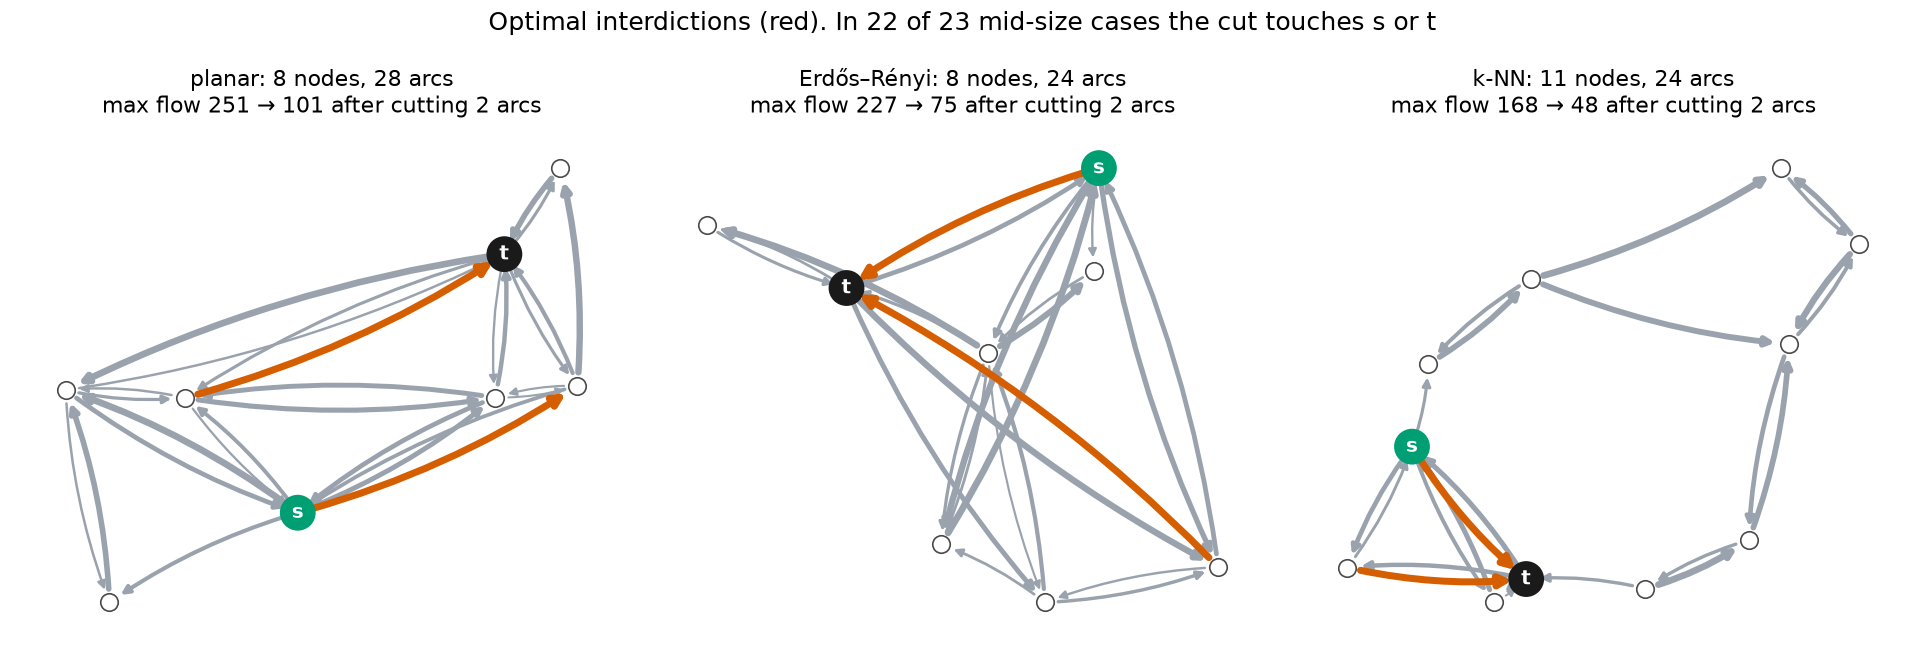

In [2]:
fig_instances = rp.plot_example_instances(mid)
save(fig_instances, "example_instances")

The QUBO from `nip_to_qubo()` has three variables per arc (*x*, *γ*, *w*)
and one per inner node (*π*), so *V* − 2 + 3*E* qubits. The plot places each
instance set against the limits that decide where it can run:
- exact statevector simulation, up to 24 qubits here;
- matrix-product-state (MPS) simulation, used for the mid-size set;
- a 156-qubit IBM Heron device.

Hollow markers show the largest piece after each slide instance is split into
pieces of at most 155 qubits (Section 5).

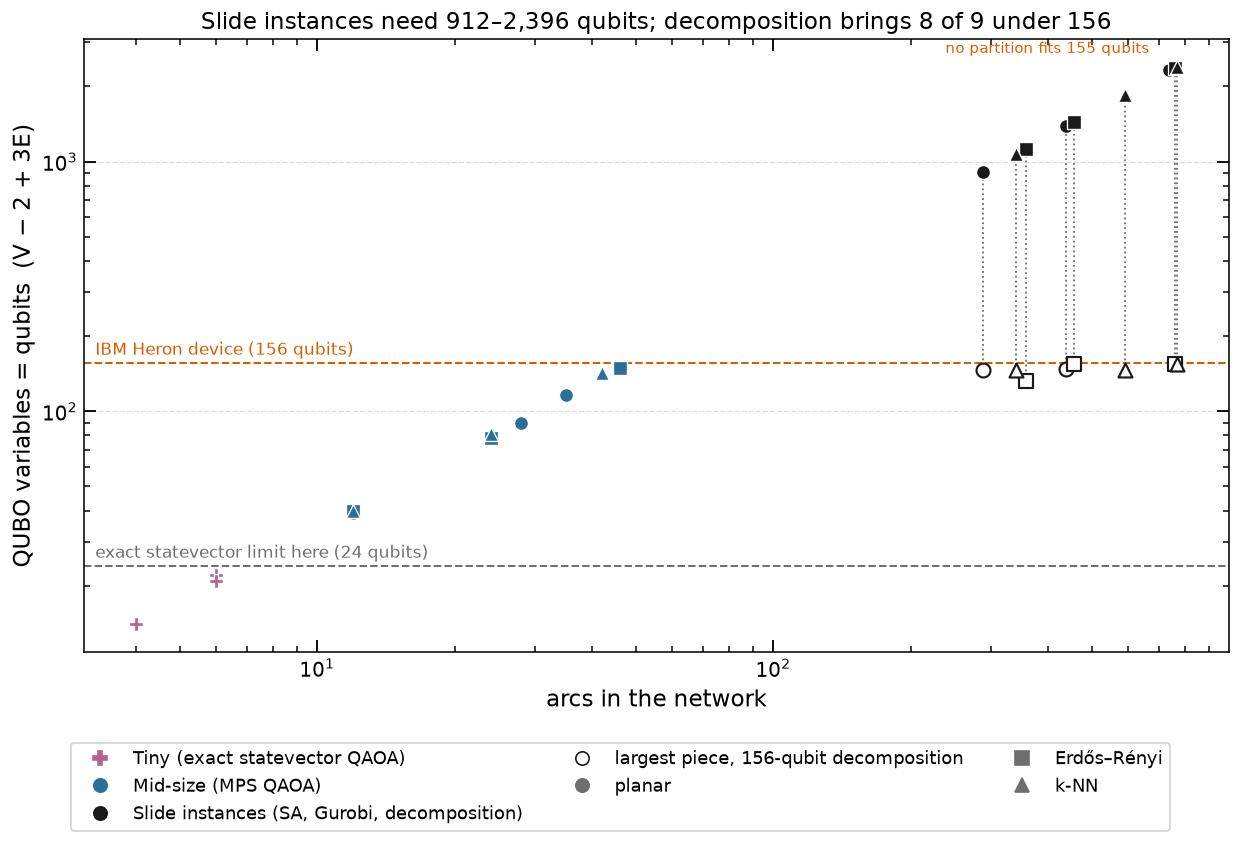

In [3]:
fig_sizes = rp.plot_problem_sizes(slide, mid, outcomes, decomposition)
save(fig_sizes, "problem_sizes")

## 2. Classical methods on the 27 slide cases

These are the 27 (network, budget) cases from the D-Wave slides, rerun
classically (#18, #20):
- **Gurobi**: the exact MILP, which proves the optimum *f\**.
- **Greedy from scratch**: repeatedly cut the arc whose removal lowers the max
  flow most.
- **SA + greedy repair**: simulated annealing on the QUBO, then greedy repair
  of its best sample.
- **Random start + repair**: the same repair applied to random plans of about
  *B* arcs, keeping the best. Any sampler has to beat this floor.

The times are wall-clock times from one run on one machine. The heuristics are
Python implementations.

In [4]:
summary = rp.classical_summary(slide)
summary.round({"median_gap": 3, "worst_gap": 3, "median_time_sec": 3})

,cases,optimal,median_gap,worst_gap,median_time_sec
method,,,,,
Gurobi (exact MILP),27,27,0.000,0.000,0.026
Greedy from scratch,27,19,0.000,0.943,9.482
SA + greedy repair,26,3,0.496,2.317,49.978
Random start + repair,27,0,1.337,8.771,21.455


Each cell is one heuristic on one case: a check mark is optimal, a number is
the gap in percent. Greedy is optimal in 19 of 27 cases. SA + repair never
beats plain greedy: it ties in 8 of its 26 cases and does worse in 18. (One
case has no valid penalty *λ*, so SA was not run on it.)

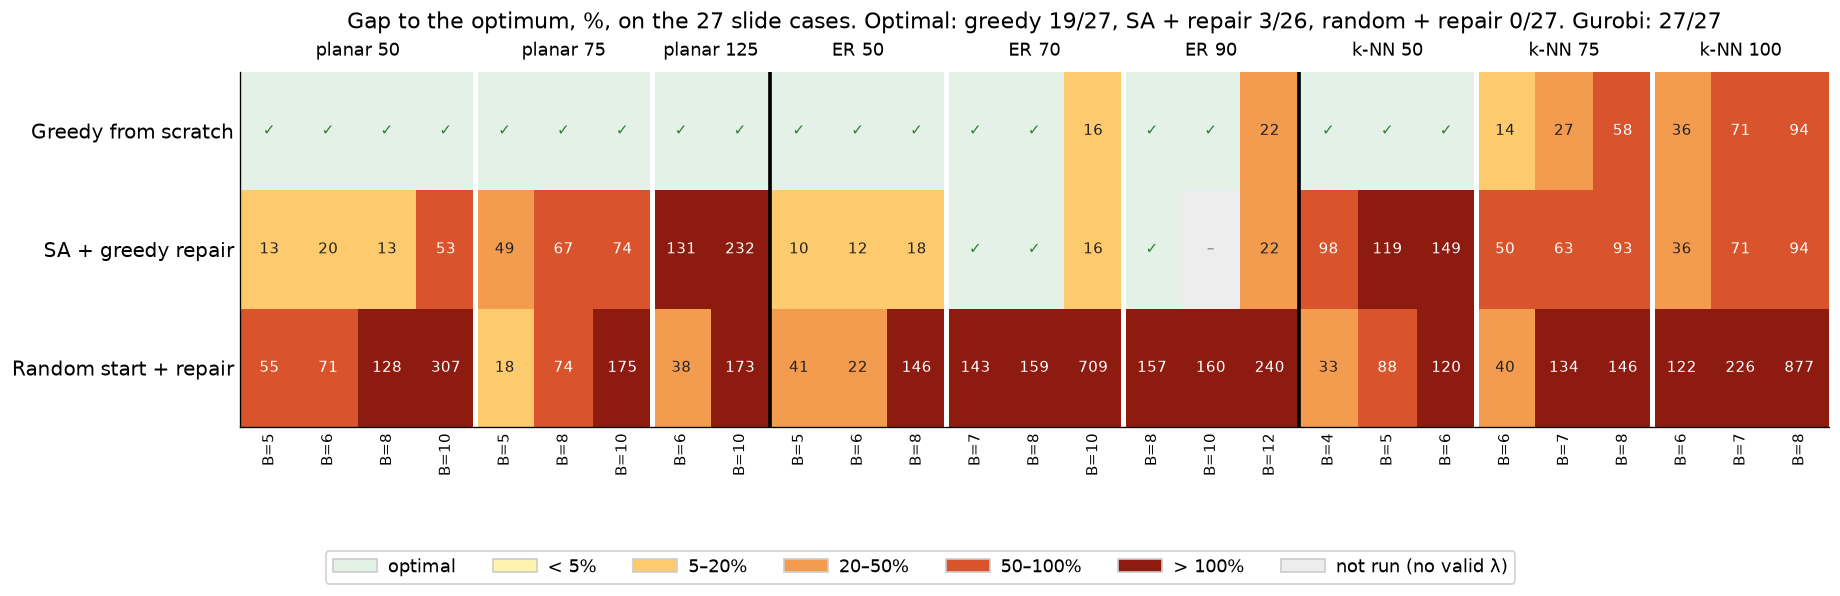

In [5]:
fig_gaps = rp.plot_classical_gaps(slide)
save(fig_gaps, "classical_gaps")

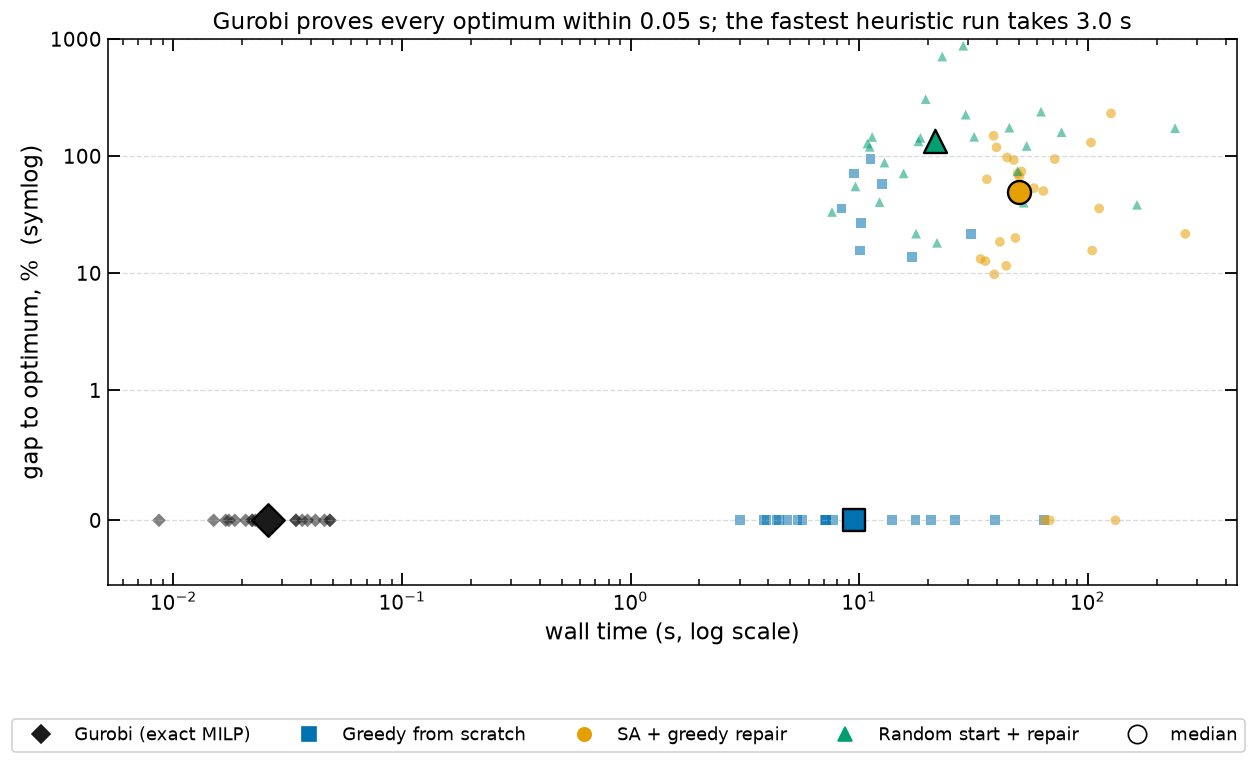

In [6]:
fig_time = rp.plot_time_vs_gap(slide)
save(fig_time, "time_vs_gap")

Gurobi proves every optimum in under 0.05 s, faster than any heuristic
finishes. These instances therefore leave no room for a quantum method to win on
time or on quality. Harder instances are the subject of issue #1 (and of open
PRs #36 and #37).

## 3. QAOA on small instances (exact simulation)

This section covers penalty QAOA (#22) on the four tiny networks (14–22
qubits), simulated exactly with Qiskit Aer. A measured bitstring proposes an
interdiction plan through its *x* bits; the other bits are auxiliary. A state is
scored by where its probability goes:
- an **optimal plan**: within budget, leaving the optimal flow;
- a plan **within budget but not optimal**;
- the **empty plan**: nothing cut, the worst possible answer;
- a plan **over budget**.

Depth 0 is the uniform superposition the circuit starts from.
`qaoa_outcomes.py` recomputes these shares from the stored angles, and every
stored P(optimal) is reproduced to within 10⁻⁶.

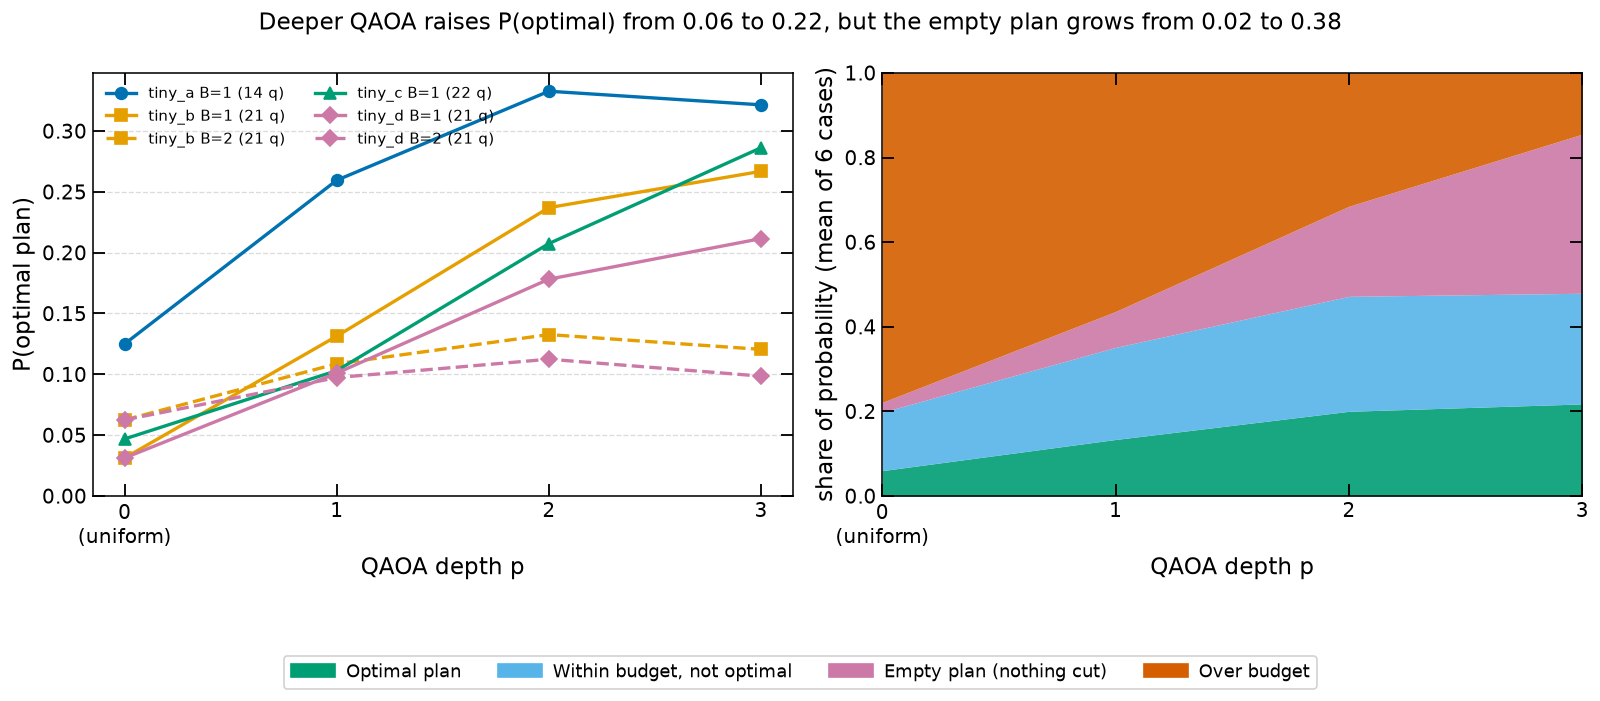

In [7]:
fig_depth = rp.plot_qaoa_depth(outcomes)
save(fig_depth, "qaoa_outcomes_depth")

Training raises P(optimal), but it also moves probability onto the empty
plan. The budget penalty makes "cut nothing" a cheap, low-energy state, so
energy-based scores (approximation ratio, gap closed) can improve while the
plans get worse. That is why this notebook scores QAOA by outcomes rather than
by energy.

### Parameter transfer (#24)

Six held-out graphs (21 qubits, *B* = 1) receive their angles in four ways:
- a fixed donor's angles;
- the angles of the nearest donor by graph features (IBM's TransferTrainer);
- the donor a graph attention network (GAT) picks;
- angles trained on the graph itself.

The regularized warm start (RWS) is a different algorithm. It starts from a
product state built from a classical relaxation of the graph's own QUBO, and
uses a matching mixer. Shaded bars are the initial states (*p* = 0).

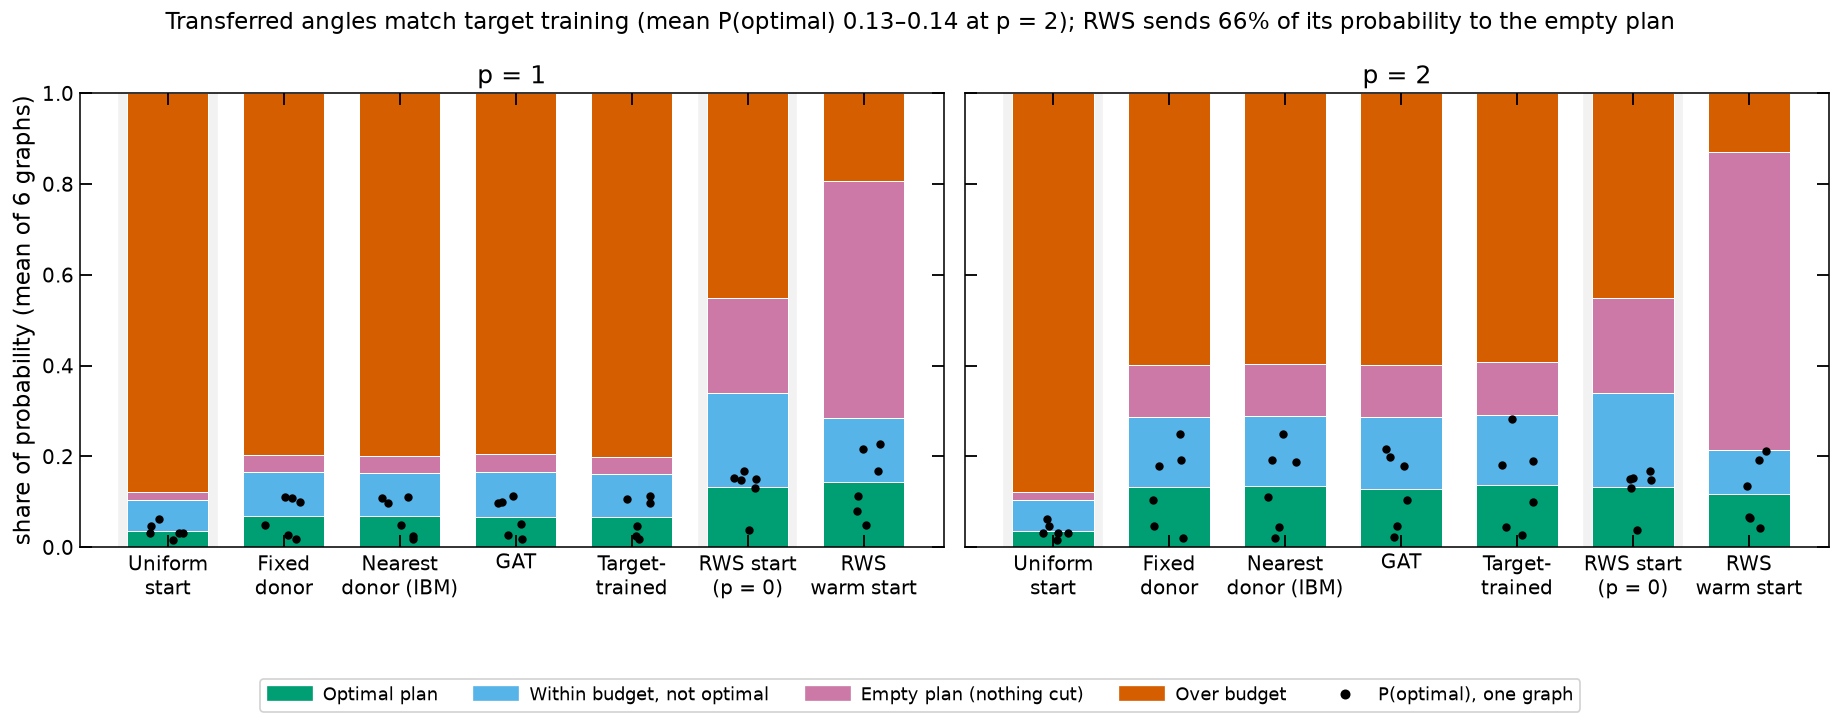

In [8]:
fig_transfer = rp.plot_transfer_outcomes(outcomes)
save(fig_transfer, "transfer_outcomes")

All four angle choices give the same outcome split, so on this cohort
transfer works as well as training, and as well as always using one donor's
angles. The cohort cannot tell the transfer methods apart.

RWS's starting state alone already reaches most of its P(optimal); its QAOA
layers then move probability onto the empty plan. Its high energy score comes
from that empty plan, not from better plans.

## 4. QAOA at 39–149 qubits (MPS simulation)

The mid-size instances (#23) are too large for a statevector. QAOA therefore
runs on Qiskit Aer's matrix-product-state simulator (bond dimension 32,
4,096 shots).
- **Donor** angles are transferred from the tiny instances.
- **Trained** angles are optimized on the instance itself; this was run up to
  81 qubits.

For comparison, a uniformly random bitstring cuts at most *B* arcs with
probability at most 1.9% on these cases, and at most 0.014% above 40 qubits.

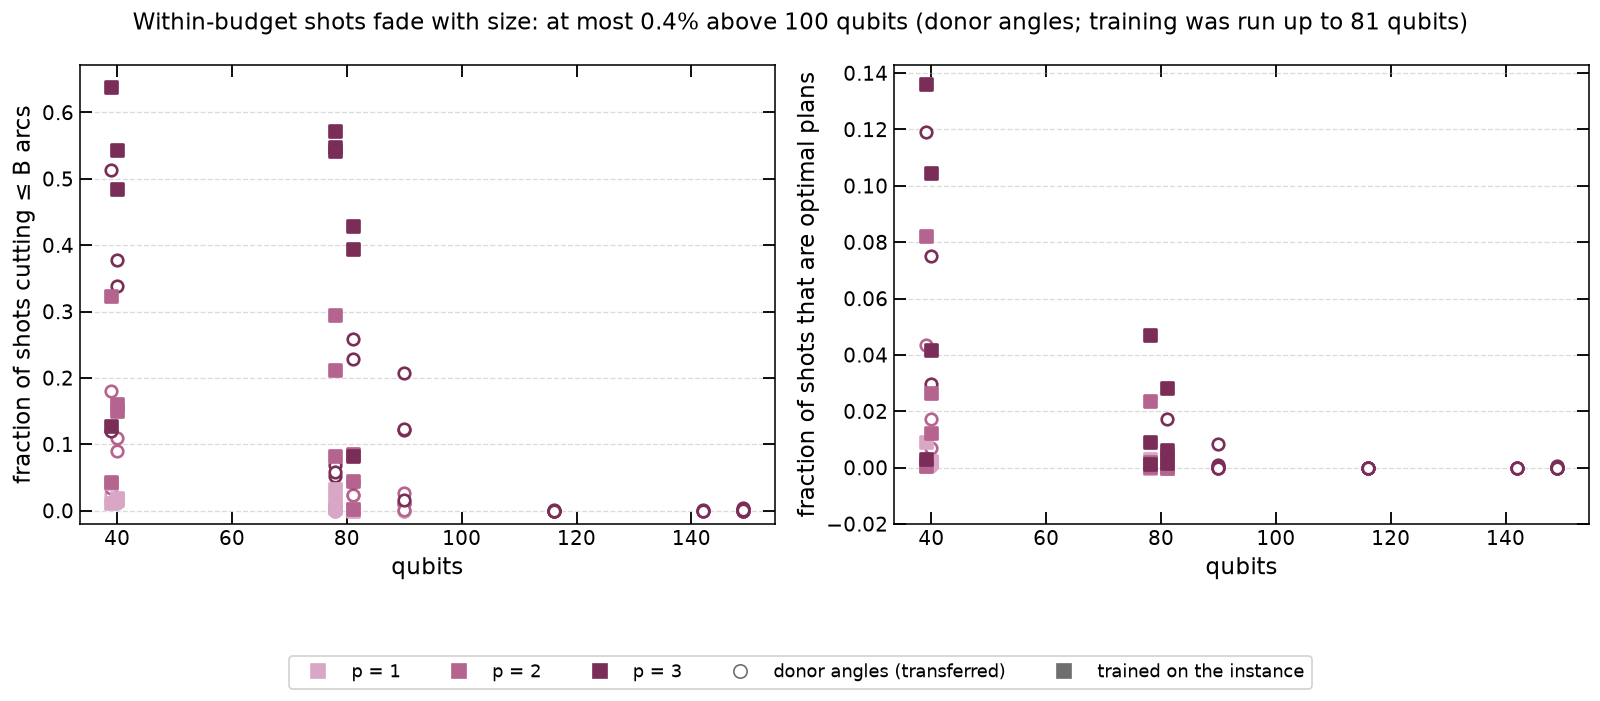

In [9]:
fig_mid = rp.plot_mid_qaoa(qaoa_mid)
save(fig_mid, "mid_qaoa")

In [10]:
repaired = qaoa_mid.assign(
    optimal_after_repair=qaoa_mid["flow_after_repair"] == qaoa_mid["opt_nip"])
mid_summary = (repaired.groupby(["angles", "reps"])
               .agg(runs=("optimal_after_repair", "size"),
                    optimal_after_repair=("optimal_after_repair", "sum"),
                    median_within_budget=("p_feasible", "median")))
mid_summary.round(4)

runs  optimal_after_repair  median_within_budget
angles reps                                                  
donor  1       23                    18                0.0000
       2       23                    18                0.0037
       3       23                    18                0.0530
train  1       10                    10                0.0132
       2       10                    10                0.1177
       3       10                    10                0.5132

Greedy repair of the best sample reaches the optimum in most runs, but that
is to the repair's credit: plain greedy is already optimal on all 23 mid-size
cases (`mid_instances.csv`).

## 5. Decomposition into device-sized pieces

Decomposition (#21, #23) works in four steps:
1. split a network into pieces;
2. give each piece part of the budget;
3. solve each piece (here exactly, with Gurobi, standing in for a quantum
   solver);
4. combine the pieces' cuts.

The budget-split rules are:
- **min-cut**: in proportion to the arcs of the global minimum cut each piece
  owns;
- **local**: in proportion to each piece's local max flow;
- **marginal**: dynamic programming over each piece's flow-versus-budget curve;
- **marginal + refine**: starts from the marginal split and moves budget units
  between pieces while the total flow drops.

Each point is one slide case in iterated mode, where every piece is re-solved
against the other pieces' cuts until nothing changes. Greedy on the whole graph
is shown for reference.

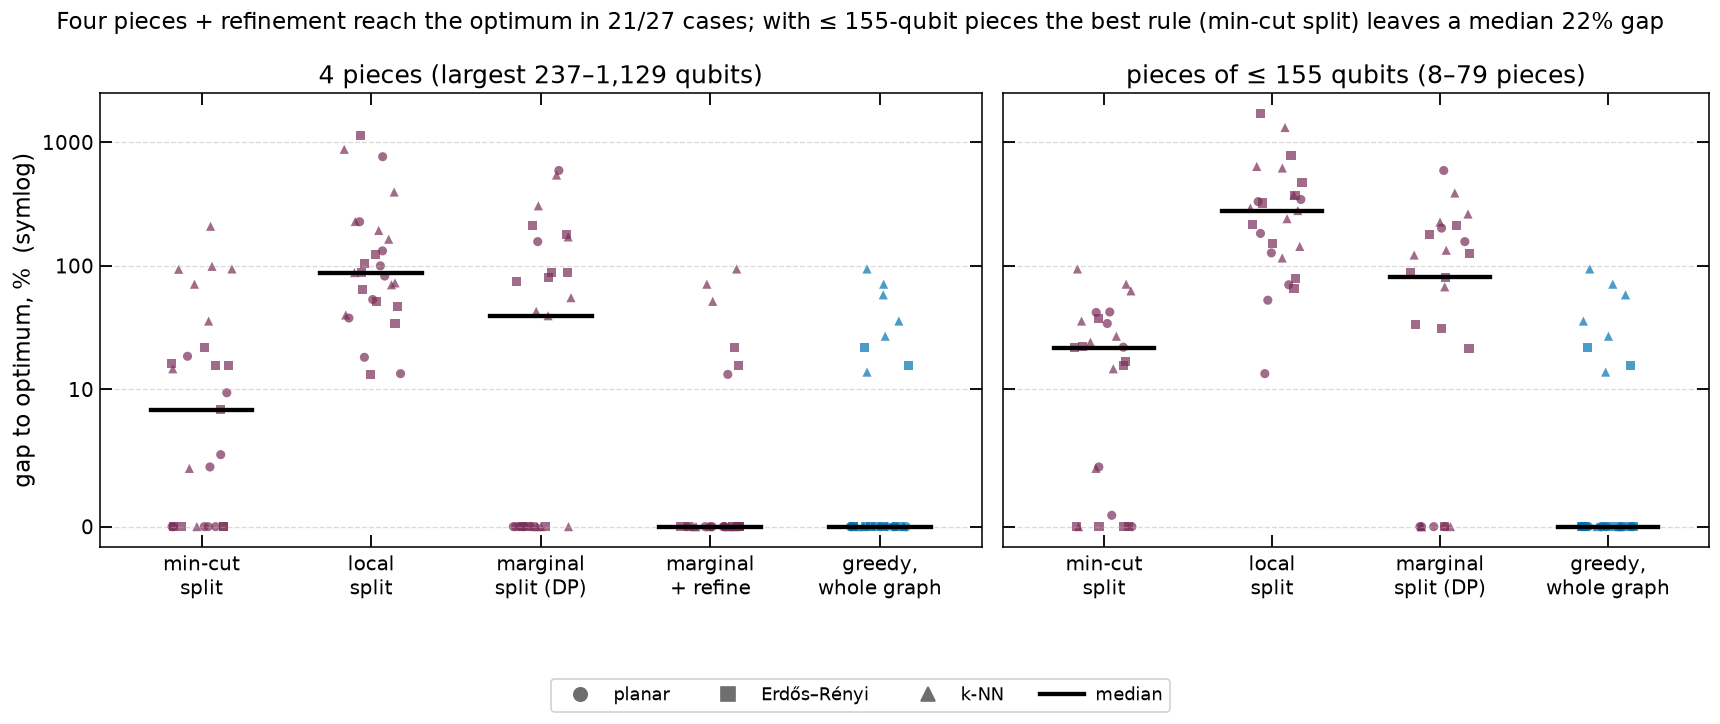

In [11]:
fig_decomposition = rp.plot_decomposition(decomposition, slide)
save(fig_decomposition, "decomposition")

With four large pieces, refinement recovers the optimum in 21 of the 27
cases. Pieces small enough for a 156-qubit device cost more: even the best rule
leaves a median gap well above greedy on the whole graph. Even with exact piece
solves, splitting the network is the bottleneck before any quantum noise
enters.

## 6. Not yet included

Results from open pull requests will be added here as each one is merged:
- LP relaxation bounds and LP round-and-repair, Lagrangian bounds (#25);
- Benders decomposition (#27) and a shared budget price (#29);
- raw annealer feasibility (#28), QCI Dirac-3 (#30) and Qiskit QAOA in the
  shared benchmark (#31);
- IBM hardware sampling (#32) and the budget-preserving XY mixer (#35);
- D-Wave embedding overhead (#33) and the squared budget penalty (#34);
- real road, contact and power networks, and harder instances (#36, #37).

The 8 October run on IBM's `ibm_fez` (tiny_a and tiny_d) is recorded locally but
not yet committed.